In [1]:
# Install / upgrade libraries if needed
# !pip install -q albumentations==1.4.3

import os, json, random, time
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import cv2
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights

import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.metrics import confusion_matrix

print("=" * 60)
print("Library versions")
print("=" * 60)
print(f"  PyTorch      : {torch.__version__}")
print(f"  Albumentations: {A.__version__}")
import torchvision
print(f"  torchvision  : {torchvision.__version__}")
print(f"  NumPy        : {np.__version__}")
print(f"  CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"  GPU           : {torch.cuda.get_device_name(0)}")
    print(f"  VRAM          : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print("=" * 60)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\nRunning on: {DEVICE}")

Library versions
  PyTorch      : 2.10.0+cu128
  Albumentations: 2.0.8
  torchvision  : 0.25.0+cu128
  NumPy        : 2.0.2
  CUDA available: True
  GPU           : Tesla T4
  VRAM          : 15.6 GB

Running on: cuda


# Load Data

In [2]:
# --- ar-plaqsegm1-ultrasound-segmentation (original dataset — images/masks) ---
SPLIT_PATH = "/kaggle/input/notebooks/yeamins/438-assignment-a/split.json"

with open(SPLIT_PATH) as f:
    split_artifact = json.load(f)

SEED           = split_artifact["seed"]
MASK_THRESHOLD = split_artifact["mask_threshold"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print(f"Loaded split -> Train: {len(split_artifact['train'])} | "
      f"Val: {len(split_artifact['val'])} | Test: {len(split_artifact['test'])}")
print(f"Seed: {SEED} | Mask threshold: {MASK_THRESHOLD}")
print(f"Removed train-side duplicates from NB0: {split_artifact['removed_train_side_duplicates']}")

Loaded split -> Train: 416 | Val: 73 | Test: 48
Seed: 42 | Mask threshold: 127
Removed train-side duplicates from NB0: ['335', '345', '346', '347']


In [3]:

# Re-point img_path / mask_path to this notebook's dataset mount
NEW_DATA_ROOT = ("/kaggle/input/datasets/yeamins/ar-plaqsegm1-ultrasound-segmentation/"
                  "Ar-PlaqSegm1 First Argentine database of B-mode ul")

def fix_paths(records, new_root):
    fixed = []
    for rec in records:
        r = rec.copy()
        for key in ["img_path", "mask_path"]:
            parts = r[key].replace("\\", "/").split("/")
            filename = os.path.join(parts[-2], parts[-1])   # e.g. train/12.png
            r[key] = os.path.join(new_root, filename)
        fixed.append(r)
    return fixed

train_records = fix_paths(split_artifact["train"], NEW_DATA_ROOT)
val_records   = fix_paths(split_artifact["val"],   NEW_DATA_ROOT)
test_records  = fix_paths(split_artifact["test"],  NEW_DATA_ROOT)

test_img = cv2.imread(train_records[0]["img_path"], cv2.IMREAD_GRAYSCALE)
assert test_img is not None, "Path fix failed — check NEW_DATA_ROOT against the attached dataset mount."
print(f"Paths verified -> sample image shape: {test_img.shape}")

Paths verified -> sample image shape: (800, 800)


In [4]:
# Same DataFrame naming convention as NB0 (train_df / val_df / test_df)
train_df = pd.DataFrame(train_records)
val_df   = pd.DataFrame(val_records)
test_df  = pd.DataFrame(test_records)

print(f"train_df: {train_df.shape} | val_df: {val_df.shape} | test_df: {test_df.shape}")
train_df.head()

train_df: (416, 5) | val_df: (73, 5) | test_df: (48, 5)


,idx,img_path,mask_path,has_plaque,hash
0,1,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,1,96bf26399b52140953e7905eb25224a9
1,100,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,1,8cfcf3f7bcebc53ea702eca3c310229e
2,101,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,1,59f5f258dddc304536136499c762965d
3,102,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,1,368f920988c28681c0df9bdc4a73a6e7
4,103,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,/kaggle/input/datasets/yeamins/ar-plaqsegm1-ul...,1,9581946e6a838dedc9a124f2d477108c


# 3. Rebuild the Augmentation Pipeline & Dataset 


In [5]:
IMG_SIZE = 512

train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=15, border_mode=cv2.BORDER_CONSTANT, p=0.3),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.4),
    A.GaussNoise(std_range=(0.02, 0.08), p=0.3),
    A.ElasticTransform(alpha=20, sigma=5, border_mode=cv2.BORDER_CONSTANT, p=0.2),
    A.Resize(IMG_SIZE, IMG_SIZE),
])

val_test_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
])

class PlaqueSegDataset(Dataset):
    def __init__(self, records_df, transform=None, mask_threshold=MASK_THRESHOLD, is_test=False):
        self.records = records_df.reset_index(drop=True)
        self.transform = transform
        self.mask_threshold = mask_threshold
        self.is_test = is_test # Added flag

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        rec = self.records.iloc[i]
        img = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)
        raw_mask = cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE)
        mask = (raw_mask > self.mask_threshold).astype("uint8")

        if self.transform:
            augmented = self.transform(image=img, mask=mask)
            img_aug, mask_aug = augmented["image"], augmented["mask"]
        else:
            img_aug, mask_aug = img, mask

        img_t = torch.from_numpy(img_aug).unsqueeze(0).float() / 255.0
        mask_t = torch.from_numpy(mask_aug).long()
        
        # If testing, return 512 input, ORIGINAL 800 mask, and the file path
        if self.is_test:
            orig_mask_t = torch.from_numpy(mask).long()
            return img_t, orig_mask_t, rec["img_path"]

        # For training/validation, return standard 512 input and 512 mask
        return img_t, mask_t

train_ds = PlaqueSegDataset(train_df, transform=train_transform)
val_ds   = PlaqueSegDataset(val_df,   transform=val_test_transform)
# Initialize test_ds with the is_test flag
test_ds  = PlaqueSegDataset(test_df,  transform=val_test_transform, is_test=True)

print(f"Dataset sizes -> train: {len(train_ds)}, val: {len(val_ds)}, test: {len(test_ds)}")

BATCH_SIZE = 8

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

Dataset sizes -> train: 416, val: 73, test: 48


## 4. Task E — Model Definition & Training

### Model: DeepLabV3-ResNet50 (`torchvision.models.segmentation`, COCO-pretrained)

- **Variant chosen**: DeepLabV3-ResNet50 (~42M params) — the recommended balanced default for this dataset size.
- Pretrained weights: `DeepLabV3_ResNet50_Weights.DEFAULT` (COCO-pretrained), classifier head replaced to output `NUM_CLASSES=2` (background / plaque).
- Grayscale ultrasound frames are replicated to 3 channels so they fit the pretrained ResNet50 stem.

# 4.1_Training Configuration
All hyperparameters are collected here in one place, as required.

In [6]:
# Dynamically calculate pixel counts since they are not in the DataFrame
total_plaque_px = 0
total_px = 0
NUM_CLASSES = 2

for mask_path in train_df["mask_path"]:
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    # Apply the same threshold used in your dataset class
    mask_bin = (mask > MASK_THRESHOLD).astype(np.uint8)
    total_plaque_px += mask_bin.sum()
    total_px += mask_bin.size

total_bg_px = total_px - total_plaque_px

# Calculate class weights
bg_weight     = total_px / (2 * total_bg_px)
plaque_weight = total_px / (2 * total_plaque_px)
class_weights = torch.tensor([bg_weight, plaque_weight], dtype=torch.float32).to(DEVICE)

CONFIG = {
    "model": "DeepLabV3-ResNet50 (torchvision, COCO-pretrained)",
    "num_classes": NUM_CLASSES,
    "input_image_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": 1e-4,
    "lr_schedule": "ReduceLROnPlateau (factor=0.5, patience=5, monitor=val_loss)",
    "loss_function": "CrossEntropyLoss (weighted)",
    "class_weights": {"background": round(bg_weight, 4), "plaque": round(plaque_weight, 4)},
    "num_epochs": 50,   # minimum floor — extend if val mIoU is still improving at epoch 50
    "seed": SEED,
    "device": str(DEVICE),
}
CONFIG

{'model': 'DeepLabV3-ResNet50 (torchvision, COCO-pretrained)',
 'num_classes': 2,
 'input_image_size': 512,
 'batch_size': 8,
 'optimizer': 'Adam',
 'learning_rate': 0.0001,
 'lr_schedule': 'ReduceLROnPlateau (factor=0.5, patience=5, monitor=val_loss)',
 'loss_function': 'CrossEntropyLoss (weighted)',
 'class_weights': {'background': np.float64(0.5065),
  'plaque': np.float64(38.9083)},
 'num_epochs': 50,
 'seed': 42,
 'device': 'cuda'}

In [7]:
#NUM_CLASSES = 2  # 0 = background, 1 = plaque
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights = DeepLabV3_ResNet50_Weights.DEFAULT
model = deeplabv3_resnet50(weights=weights, aux_loss=True)

# 1. Update the main classifier for 2 classes
model.classifier[4] = nn.Conv2d(256, NUM_CLASSES, kernel_size=1)
model.aux_classifier= None 
model = model.to(DEVICE)

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def preprocess(imgs_1ch):
    """(B,1,H,W) grayscale in [0,1] -> (B,3,H,W) ImageNet-normalized, on DEVICE."""
    imgs_3ch = imgs_1ch.repeat(1, 3, 1, 1)
    imgs_3ch = (imgs_3ch - IMAGENET_MEAN.to(imgs_1ch.device)) / IMAGENET_STD.to(imgs_1ch.device)
    return imgs_3ch.to(DEVICE)

print("Main Classifier Layer:", model.classifier[4])


Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:01<00:00, 152MB/s]


Main Classifier Layer: Conv2d(256, 2, kernel_size=(1, 1), stride=(1, 1))


## 4.2_Training Loop

In [8]:
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)

def compute_confusion(preds, targets, num_classes=NUM_CLASSES):
    return confusion_matrix(targets.flatten(), preds.flatten(), labels=list(range(num_classes)))

def miou_from_confusion(conf):
    ious = []
    for c in range(conf.shape[0]):
        tp = conf[c, c]
        fp = conf[:, c].sum() - tp
        fn = conf[c, :].sum() - tp
        denom = tp + fp + fn
        ious.append(tp / denom if denom > 0 else np.nan)
    return np.nanmean(ious), ious

history = {"train_loss": [], "val_loss": [], "val_miou": []}
best_val_miou = -1.0
start_time = time.time()

for epoch in range(1, CONFIG["num_epochs"] + 1):
    # --- train ---
    model.train()
    running_loss = 0.0
    for imgs, masks in train_loader:
        imgs, masks = preprocess(imgs), masks.to(DEVICE)
        optimizer.zero_grad()
        out = model(imgs)["out"]
        loss = criterion(out, masks)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
    train_loss = running_loss / len(train_ds)

    # --- validate ---
    model.eval()
    running_vloss = 0.0
    conf_total = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs_p, masks_d = preprocess(imgs), masks.to(DEVICE)
            out = model(imgs_p)["out"]
            loss = criterion(out, masks_d)
            running_vloss += loss.item() * imgs.size(0)
            preds = out.argmax(dim=1).cpu().numpy()
            conf_total += compute_confusion(preds, masks.numpy())
    val_loss = running_vloss / len(val_ds)
    val_miou, _ = miou_from_confusion(conf_total)

    scheduler.step(val_loss)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_miou"].append(val_miou)

    if val_miou > best_val_miou:
        best_val_miou = val_miou
        torch.save(model.state_dict(), "best_deeplabv3_resnet50.pt")

    print(f"Epoch {epoch:03d}/{CONFIG['num_epochs']} | "
          f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_mIoU={val_miou:.4f}")

CONFIG["total_training_time_sec"] = round(time.time() - start_time, 1)
CONFIG["best_val_miou"] = round(float(best_val_miou), 4)
print(f"\nTotal training time: {CONFIG['total_training_time_sec']/60:.1f} min")
print(f"Best validation mIoU: {CONFIG['best_val_miou']}")

Epoch 001/50 | train_loss=0.3919 | val_loss=0.2810 | val_mIoU=0.5061
Epoch 002/50 | train_loss=0.2357 | val_loss=0.1879 | val_mIoU=0.5500
Epoch 003/50 | train_loss=0.1730 | val_loss=0.1579 | val_mIoU=0.6020
Epoch 004/50 | train_loss=0.1460 | val_loss=0.1430 | val_mIoU=0.5621
Epoch 005/50 | train_loss=0.1249 | val_loss=0.1258 | val_mIoU=0.6112
Epoch 006/50 | train_loss=0.1062 | val_loss=0.1412 | val_mIoU=0.6199
Epoch 007/50 | train_loss=0.1093 | val_loss=0.1123 | val_mIoU=0.6112
Epoch 008/50 | train_loss=0.0947 | val_loss=0.1324 | val_mIoU=0.6157
Epoch 009/50 | train_loss=0.0944 | val_loss=0.1315 | val_mIoU=0.5868
Epoch 010/50 | train_loss=0.0810 | val_loss=0.0981 | val_mIoU=0.6291
Epoch 011/50 | train_loss=0.0743 | val_loss=0.1131 | val_mIoU=0.6276
Epoch 012/50 | train_loss=0.0688 | val_loss=0.1440 | val_mIoU=0.6410
Epoch 013/50 | train_loss=0.0667 | val_loss=0.1267 | val_mIoU=0.6522
Epoch 014/50 | train_loss=0.0607 | val_loss=0.1321 | val_mIoU=0.6459
Epoch 015/50 | train_loss=0.0718 |

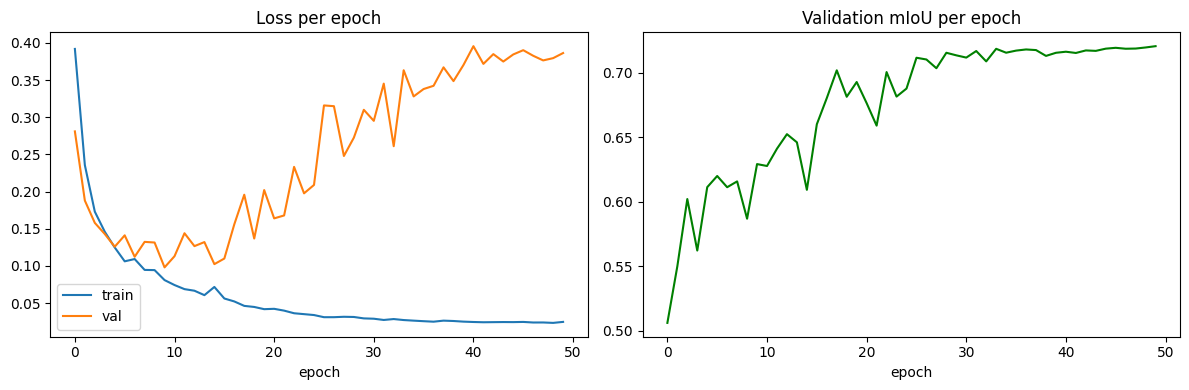

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Loss per epoch"); axes[0].set_xlabel("epoch"); axes[0].legend()

axes[1].plot(history["val_miou"], color="green")
axes[1].set_title("Validation mIoU per epoch"); axes[1].set_xlabel("epoch")

plt.tight_layout()
plt.show()

# 5. Task F — Testing & Quantitative Evaluation

Running evaluation on the held-out test split (800x800 resolution)...

TASK F: TESTING & QUANTITATIVE EVALUATION RESULTS
Overall Pixel Accuracy: 0.9919
Mean Pixel Accuracy:    0.8815
Mean IoU (mIoU):        0.7195
Mean Dice Coefficient:  0.8070
--------------------------------------------------
Per-Class Metrics:
  Background (0) -> IoU: 0.9918 | Dice: 0.9959
  Plaque (1) -> IoU: 0.4472 | Dice: 0.6180

Pixel-Level Confusion Matrix Values:
[[30267663   189324]
 [   60719   202294]]


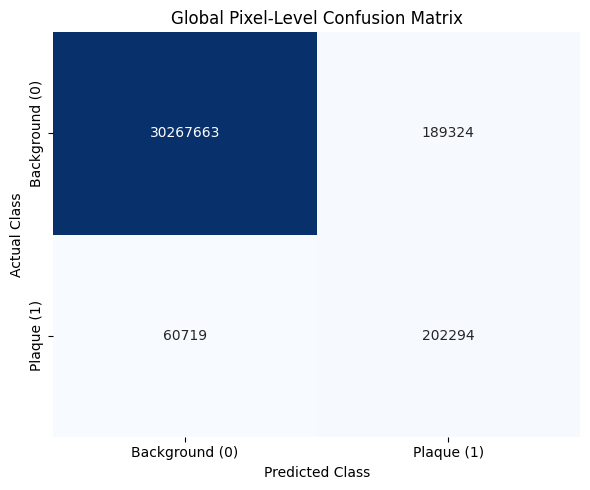

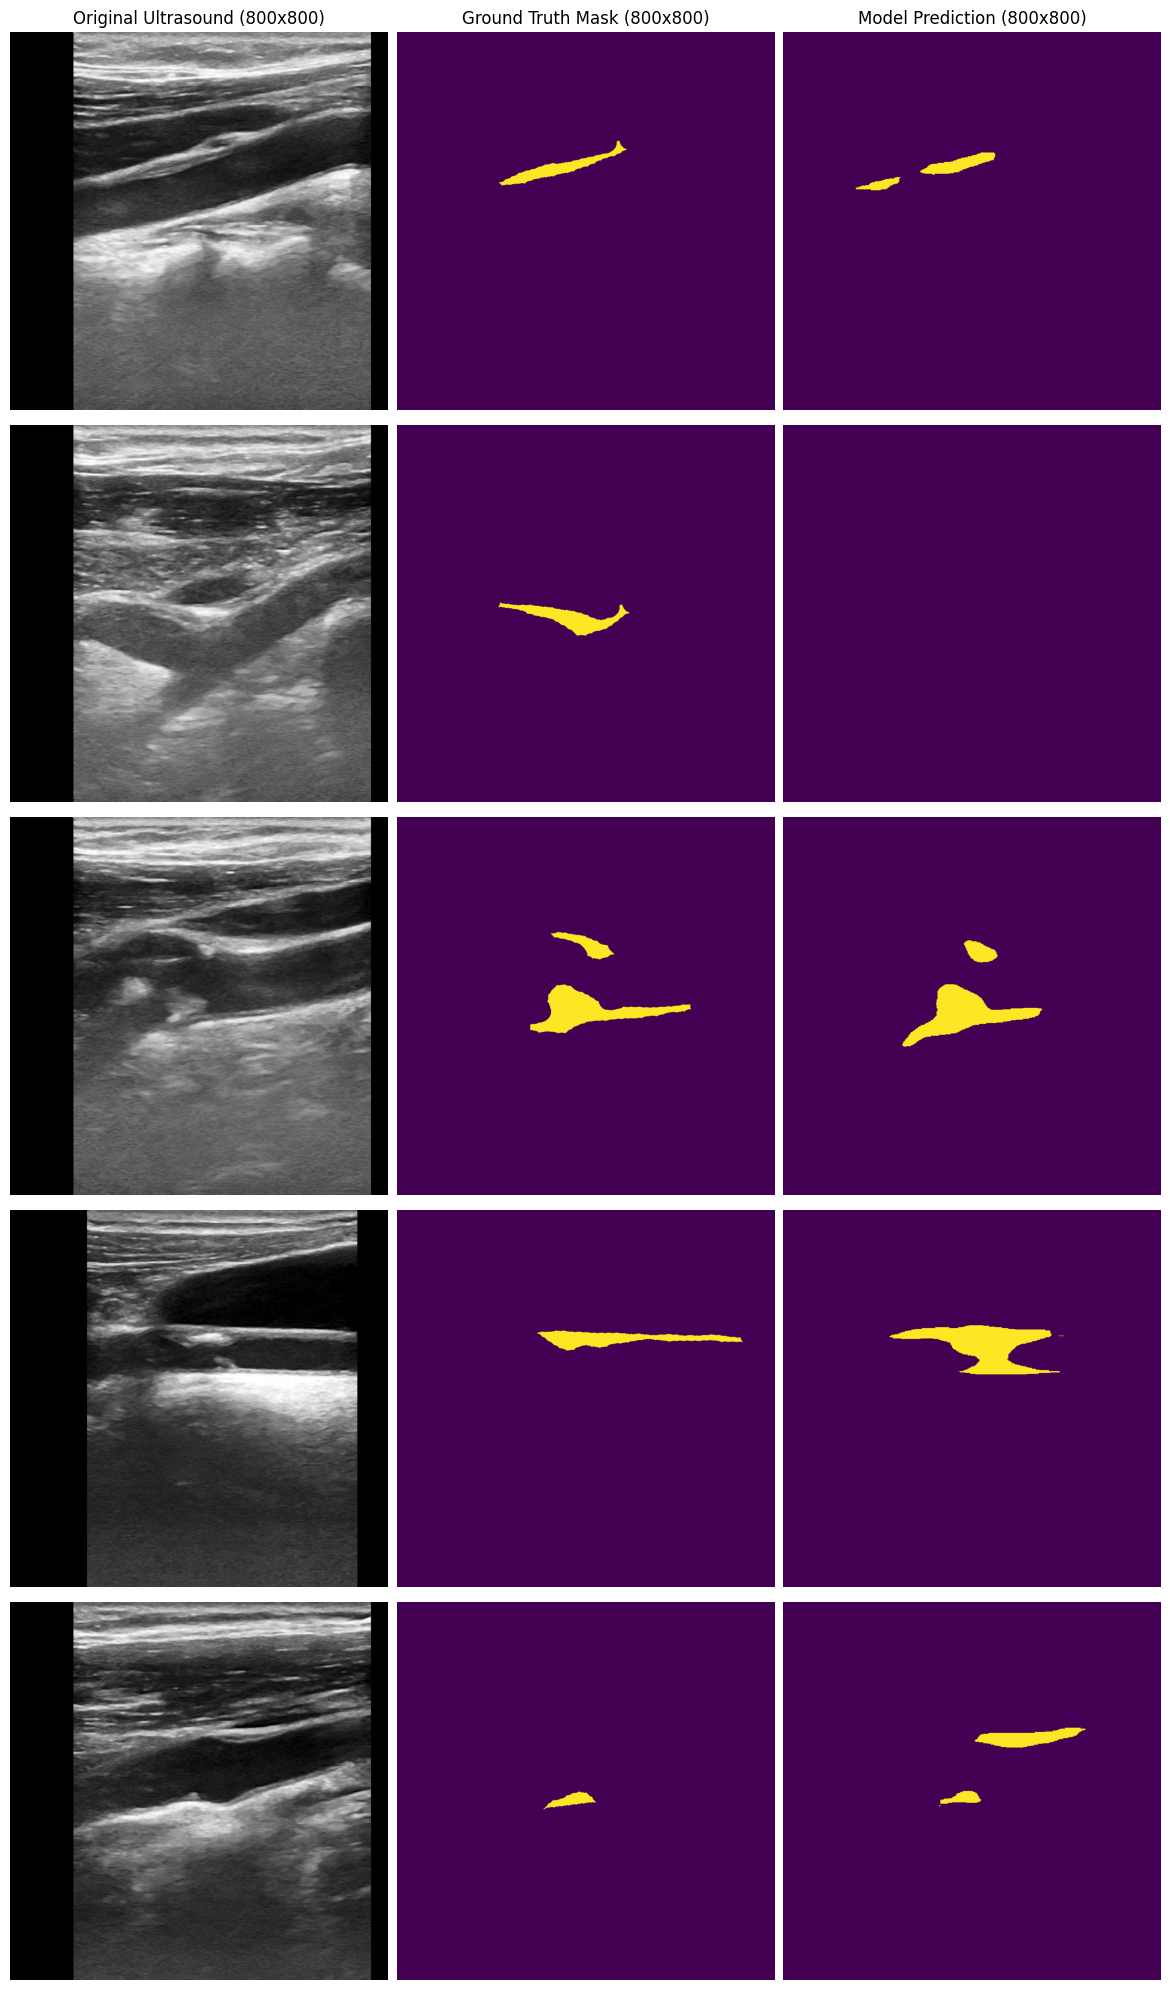

In [10]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import cv2

# 1. Load the model and set to evaluation mode
model.load_state_dict(torch.load("best_deeplabv3_resnet50.pt"))
model.eval()

# 2. Trackers for quantitative evaluation and visuals
global_conf = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

sample_raw_imgs = []
sample_true_masks = []
sample_pred_masks = []
num_visuals = 5

print("Running evaluation on the held-out test split (800x800 resolution)...")

# 3. Evaluation Loop
with torch.no_grad():
    for imgs, orig_masks, paths in test_loader:
        # Preprocess 512x512 image for the model
        imgs_p = preprocess(imgs)
        
        # Get 512x512 prediction
        out = model(imgs_p)["out"]
        preds_512 = out.argmax(dim=1).float().unsqueeze(1)
        
        # Upscale prediction to original mask dimensions (800x800) using nearest neighbor
        preds_800 = F.interpolate(preds_512, size=orig_masks.shape[1:], mode="nearest").squeeze(1).cpu().numpy()
        orig_masks_np = orig_masks.numpy()
        
        # Compute metrics and store samples
        for i in range(len(imgs)):
            true_mask = orig_masks_np[i]
            pred_mask = preds_800[i]
            
            # Accumulate global pixel-level confusion matrix
            global_conf += confusion_matrix(
                true_mask.flatten(), 
                pred_mask.flatten(), 
                labels=list(range(NUM_CLASSES))
            )
            
            # Save a few *plaque-containing* images for visual plotting.
            # (Fix: the old version grabbed whichever images came first in the
            # test set regardless of content, so if those first images had no
            # plaque pixels at all, both GT and prediction panels rendered as a
            # single solid color. We now require true_mask.sum() > 0 so the
            # qualitative panel actually shows plaque segmentation.)
            if len(sample_raw_imgs) < num_visuals and true_mask.sum() > 0:
                sample_raw_imgs.append(cv2.imread(paths[i], cv2.IMREAD_GRAYSCALE))
                sample_true_masks.append(true_mask)
                sample_pred_masks.append(pred_mask)

# 4. Calculate Metrics from the Global Confusion Matrix
TP = np.diag(global_conf)
FP = global_conf.sum(axis=0) - TP
FN = global_conf.sum(axis=1) - TP

# IoU
per_class_iou = TP / (TP + FP + FN + 1e-6)
mIoU = np.nanmean(per_class_iou)

# Accuracies
overall_pixel_acc = TP.sum() / global_conf.sum()
per_class_acc = TP / (TP + FN + 1e-6)
mean_pixel_acc = np.nanmean(per_class_acc)

# Dice Coefficient (F1 Score)
per_class_dice = (2 * TP) / ((2 * TP) + FP + FN + 1e-6)
mean_dice = np.nanmean(per_class_dice)

# 5. Print Quantitative Values
print("\n" + "="*50)
print("TASK F: TESTING & QUANTITATIVE EVALUATION RESULTS")
print("="*50)
print(f"Overall Pixel Accuracy: {overall_pixel_acc:.4f}")
print(f"Mean Pixel Accuracy:    {mean_pixel_acc:.4f}")
print(f"Mean IoU (mIoU):        {mIoU:.4f}")
print(f"Mean Dice Coefficient:  {mean_dice:.4f}")
print("-" * 50)
print("Per-Class Metrics:")
class_names = ["Background (0)", "Plaque (1)"]
for c in range(NUM_CLASSES):
    print(f"  {class_names[c]} -> IoU: {per_class_iou[c]:.4f} | Dice: {per_class_dice[c]:.4f}")
print("="*50)

print("\nPixel-Level Confusion Matrix Values:")
print(global_conf)

# 6. Visualizations: Confusion Matrix Plot
plt.figure(figsize=(6, 5))
sns.heatmap(global_conf, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.title('Global Pixel-Level Confusion Matrix')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.show()

# 7. Visualizations: Sample Predictions (Original vs GT vs Pred)
if len(sample_raw_imgs) == 0:
    print("No plaque-containing test images were found for the qualitative panel.")
else:
    n_show = len(sample_raw_imgs)
    fig, axes = plt.subplots(n_show, 3, figsize=(12, 4 * n_show))
    if n_show == 1:
        axes = axes.reshape(1, 3)
    plt.subplots_adjust(wspace=0.1, hspace=0.2)

    axes[0, 0].set_title("Original Ultrasound (800x800)", fontsize=12)
    axes[0, 1].set_title("Ground Truth Mask (800x800)", fontsize=12)
    axes[0, 2].set_title("Model Prediction (800x800)", fontsize=12)

    for i in range(n_show):
        axes[i, 0].imshow(sample_raw_imgs[i], cmap='gray')
        axes[i, 0].axis('off')
        
        # vmin/vmax pinned to 0/1 so the colormap is always anchored to the
        # same two classes, whether or not plaque pixels are present.
        axes[i, 1].imshow(sample_true_masks[i], cmap='viridis', vmin=0, vmax=1)
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow(sample_pred_masks[i], cmap='viridis', vmin=0, vmax=1)
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()


# 6 Task-- G Error Analysis

In [11]:
import json
import torch
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import confusion_matrix

# 1. Initialize trackers for global and per-image metrics
global_conf = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
per_image_results_list = []
current_idx = 0

print("Running unified evaluation and gathering metrics data...")

model.eval()
with torch.no_grad():
    for imgs, orig_masks, paths in test_loader:
        # Preprocess for model (512x512 inference)
        imgs_p = preprocess(imgs)
        out = model(imgs_p)["out"]
        
        # Get predictions and upscale to match 800x800 ground truth dimensions
        preds_512 = out.argmax(dim=1).float().unsqueeze(1)
        preds_800 = F.interpolate(preds_512, size=orig_masks.shape[1:], mode="nearest").squeeze(1).cpu().numpy()
        orig_masks_np = orig_masks.numpy()
        
        for i in range(len(imgs)):
            true_mask = orig_masks_np[i]
            pred_mask = preds_800[i]
            
            # --- 1. Accumulate Global Metrics (Optimized Vectorization with Int Cast) ---
            comb = NUM_CLASSES * true_mask.flatten() + pred_mask.flatten()
            comb = comb.astype(np.int64) # <-- Fixes the float64 to int64 casting error
            
            img_conf = np.bincount(comb, minlength=NUM_CLASSES**2).reshape(NUM_CLASSES, NUM_CLASSES)
            global_conf += img_conf
            
            # --- 2. Extract Individual Image Metrics ---
            img_tp = np.diag(img_conf)
            img_fp = img_conf.sum(axis=0) - img_tp
            img_fn = img_conf.sum(axis=1) - img_tp
            
            # Per-image IoUs
            img_ious = img_tp / (img_tp + img_fp + img_fn + 1e-6)
            
            # Plaque-specific handling mirroring your original zero-union criteria
            plaque_union = np.logical_or(pred_mask == 1, true_mask == 1).sum()
            plaque_iou_val = 1.0 if plaque_union == 0 else img_ious[1]
            
            per_image_results_list.append({
                "idx": int(current_idx),
                "plaque_iou": float(round(plaque_iou_val, 4)),
                "mIoU": float(round(np.nanmean(img_ious), 4))
            })
            current_idx += 1

# 3. Calculate Global Metrics from Accumulated Matrix
TP = np.diag(global_conf)
FP = global_conf.sum(axis=0) - TP
FN = global_conf.sum(axis=1) - TP

per_class_iou = TP / (TP + FP + FN + 1e-6)
per_class_dice = (2 * TP) / ((2 * TP) + FP + FN + 1e-6)
per_class_acc = TP / (TP + FN + 1e-6)

# 4. Construct the structured summary dictionary
output_summary = {
    "model": "DeepLabV3_ResNet50",
    "test_metrics": {
        "mIoU": float(round(np.nanmean(per_class_iou), 4)),
        "iou_background": float(round(per_class_iou[0], 4)),
        "iou_plaque": float(round(per_class_iou[1], 4)),
        "overall_pixel_acc": float(round(TP.sum() / global_conf.sum(), 4)),
        "mean_pixel_acc": float(round(np.nanmean(per_class_acc), 4)),
        "mean_dice": float(round(np.nanmean(per_class_dice), 4)),
        "dice_background": float(round(per_class_dice[0], 4)),
        "dice_plaque": float(round(per_class_dice[1], 4)),
        "confusion_matrix": global_conf.tolist()
    },
    "per_image_results": per_image_results_list
}

# 5. Output the results cleanly to terminal and save JSON file
json_output = json.dumps(output_summary, indent=4)
print("Evaluation Complete. Previewing JSON structure:\n")
print(json_output[:1000] + "\n... [truncated for preview] ...")

# Explicitly save the generated text string into a file
with open("evaluation_summary.json", "w") as f:
    f.write(json_output)

print("\nSuccessfully saved results to 'evaluation_summary.json'")

Running unified evaluation and gathering metrics data...
Evaluation Complete. Previewing JSON structure:

{
    "model": "DeepLabV3_ResNet50",
    "test_metrics": {
        "mIoU": 0.7195,
        "iou_background": 0.9918,
        "iou_plaque": 0.4472,
        "overall_pixel_acc": 0.9919,
        "mean_pixel_acc": 0.8815,
        "mean_dice": 0.807,
        "dice_background": 0.9959,
        "dice_plaque": 0.618,
        "confusion_matrix": [
            [
                30267663,
                189324
            ],
            [
                60719,
                202294
            ]
        ]
    },
    "per_image_results": [
        {
            "idx": 0,
            "plaque_iou": 1.0,
            "mIoU": 0.5
        },
        {
            "idx": 1,
            "plaque_iou": 1.0,
            "mIoU": 0.5
        },
        {
            "idx": 2,
            "plaque_iou": 1.0,
            "mIoU": 0.5
        },
        {
            "idx": 3,
            "plaque_iou": 1.0,


Scanning test set for worst-performing images...

Top 3 Worst Images (Lowest Plaque IoU):
  1. Index 6 - IoU: 0.0000
  2. Index 8 - IoU: 0.0000
  3. Index 16 - IoU: 0.0000


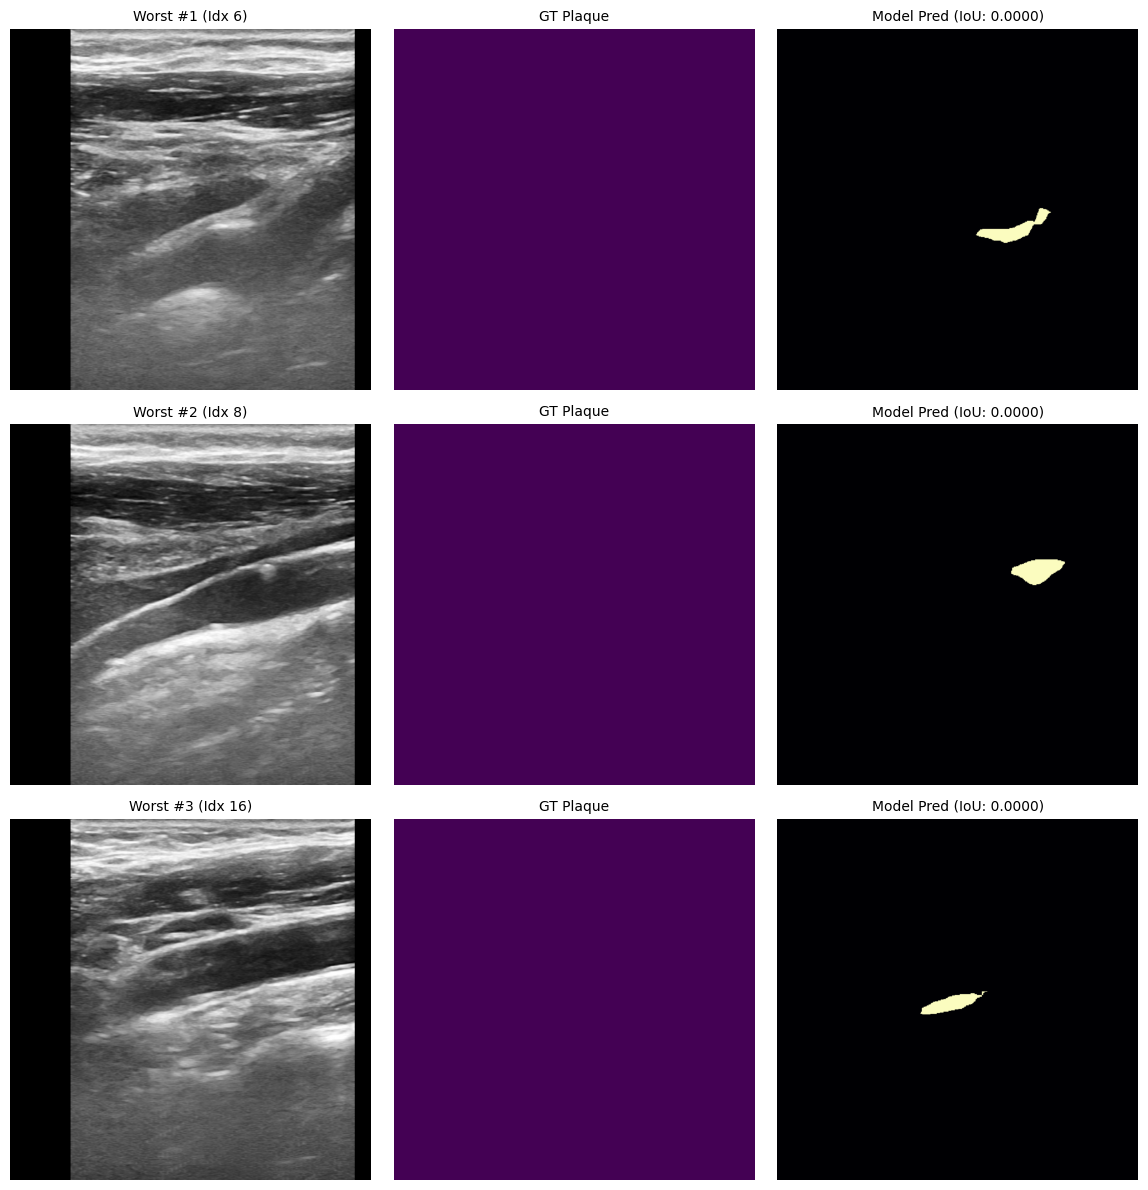

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

model.eval()
per_image_results = []
current_idx = 0

print("Scanning test set for worst-performing images...")

with torch.no_grad():
    # Make sure to catch 'paths' since your test_loader yields 3 items!
    for imgs, masks, paths in test_loader:
        imgs_p = preprocess(imgs)
        out = model(imgs_p)["out"]
        
        # Keep as torch tensor and add a channel dimension for interpolation: (B, 1, 512, 512)
        preds_512 = out.argmax(dim=1).float().unsqueeze(1)
        
        # CRITICAL STEP: Upscale the 512x512 predictions to 800x800 to match the ground truth masks
        preds_800 = F.interpolate(preds_512, size=(800, 800), mode="nearest").squeeze(1).cpu().numpy()
        true_masks_800 = masks.numpy() # These are already 800x800 from the dataset
        
        for i in range(len(imgs)):
            pred = preds_800[i]       # Now safely (800, 800)
            true = true_masks_800[i]  # Safely (800, 800)
            
            # Focus on Plaque class (Class 1)
            intersection = np.logical_and(pred == 1, true == 1).sum()
            union = np.logical_or(pred == 1, true == 1).sum()
            
            if union == 0:
                # If ground truth has no plaque and model predicted no plaque, it's a perfect score.
                iou = 1.0 
            else:
                iou = intersection / union
                
            per_image_results.append({
                "iou": iou,
                "dataset_idx": current_idx
            })
            current_idx += 1

# Sort by lowest IoU first
per_image_results.sort(key=lambda x: x["iou"])
worst_images = per_image_results[:3]

print("\nTop 3 Worst Images (Lowest Plaque IoU):")
for rank, item in enumerate(worst_images, 1):
    print(f"  {rank}. Index {item['dataset_idx']} - IoU: {item['iou']:.4f}")

# --- VISUALIZE THE FAILURE MODES ---
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
plt.subplots_adjust(wspace=0.1, hspace=0.3)

# Go back through the loader or extract explicitly from test_dataset using the index
for rank, item in enumerate(worst_images):
    idx = item['dataset_idx']
    
    # Retrieve the raw data using the dataset index
    img_tensor, true_mask_tensor, img_path = test_loader.dataset[idx]
    
    # Generate model prediction for this specific image
    img_p = preprocess(img_tensor.unsqueeze(0)) # Add batch dim
    with torch.no_grad():
        out = model(img_p)["out"]
    pred_512 = out.argmax(dim=1).float().unsqueeze(1)
    pred_800 = F.interpolate(pred_512, size=(800, 800), mode="nearest").squeeze().cpu().numpy()
    
    raw_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    true_mask = true_mask_tensor.numpy()
    
    # Plotting column 1: Raw Image
    axes[rank, 0].imshow(raw_img, cmap='gray')
    axes[rank, 0].set_title(f"Worst #{rank+1} (Idx {idx})", fontsize=10)
    axes[rank, 0].axis('off')
    
    # Plotting column 2: Ground Truth
    axes[rank, 1].imshow(true_mask, cmap='viridis')
    axes[rank, 1].set_title(f"GT Plaque", fontsize=10)
    axes[rank, 1].axis('off')
    
    # Plotting column 3: Prediction
    axes[rank, 2].imshow(pred_800, cmap='magma')
    axes[rank, 2].set_title(f"Model Pred (IoU: {item['iou']:.4f})", fontsize=10)
    axes[rank, 2].axis('off')

plt.tight_layout()
plt.show()